In [9]:
import sys
import pandas as pd
from pathlib import Path
from dotenv import load_dotenv
load_dotenv()

current = Path.cwd()

if (current / "app").is_dir():
    project_root = current
elif (current.parent / "app").is_dir():
    project_root = current.parent
else:
    raise FileNotFoundError("Cannot find the app folder")

sys.path.insert(0, str(project_root))

## 1. What is the actual data?
**Grain:** one row per `(month, region, product category)`. Six months × four regions × three categories = **72 rows**.

| Column | Meaning | Example |
|---|---|---|
| `month` | calendar month | `2026-10` |
| `region` | sales geography | `West` |
| `product` | retail category | `Electronics` |
| `revenue` | rupees earned | `1,517,?` (inspect exact CSV) |
| `units` | units sold | integer |
| `cogs` | cost of goods sold (₹) | decimal |
| `promo_spend` | promotion expense (₹) | decimal |
| `stockout_days` | count of unavailable days | integer |

In [4]:
df = pd.read_csv("../data/retail_performance.csv")
df.head()

,month,region,product,revenue,units,cogs,promo_spend,stockout_days
0,2026-05,East,Electronics,2270000.0,2671,1543600.0,95340.0,0
1,2026-05,East,Grocery,2990000.0,2431,1853800.0,125580.0,0
2,2026-05,East,Home,2630000.0,2529,1630600.0,110460.0,0
3,2026-05,North,Electronics,1890000.0,2224,1285200.0,79380.0,0
4,2026-05,North,Grocery,2610000.0,2122,1618200.0,109620.0,0


In [5]:
display(df.query("region == 'West' and month in ['2026-09', '2026-10']")
        .sort_values(["month", "product"]).reset_index(drop=True))

,month,region,product,revenue,units,cogs,promo_spend,stockout_days
0,2026-09,West,Electronics,1890400.0,2224,1285472.00,79396.80,0
1,2026-09,West,Grocery,2691040.0,2188,1668444.80,113023.68,0
2,2026-09,West,Home,2290720.0,2203,1420246.40,96210.24,0
3,2026-10,West,Electronics,1472880.0,1733,1001558.40,110466.00,11
4,2026-10,West,Grocery,2648448.0,2153,1642037.76,198633.60,2
5,2026-10,West,Home,2160528.0,2077,1339527.36,162039.60,4


## Explorations of Agents


In [11]:
from app.database import connect
from app.analytics import sales, inventory, finance

In [13]:
from app.workflow import model, get_sales_metrics, get_inventory_metrics, get_finance_metrics
from langchain.agents import create_agent

In [ ]:
sales_agent = create_agent(
model=model(),
tools=[get_sales_metrics],
 system_prompt="""
You are a retail Sales Analyst.
Always call get_sales_metrics before answering.
IMPORTANT:
Convert all months to YYYY-MM format before tool calls.
Examples:
October 2026 -> 2026-10
September 2026 -> 2026-09
Use only verified tool data.
"""

)

In [15]:
sales_result = sales_agent.invoke({"messages":[{"role":"user","content":"Explain West October 2026 revenue compared to September 2026. Use the sales tool."}]})


In [17]:
print("SALES ANSWER:\n", sales_result["messages"][-1].content)


SALES ANSWER:
 In the West region, the revenue for October 2026 was $6,281,856, which represents a decrease of 8.59% compared to September 2026, when the revenue was $6,872,160.

Breaking it down by product categories:
- Grocery revenue decreased by 1.58%, from $2,691,040 in September to $2,648,448 in October.
- Home product revenue decreased by 5.68%, from $2,290,720 in September to $2,160,528 in October.
- Electronics revenue saw the largest drop of 22.09%, from $1,890,400 in September to $1,472,880 in October.

Overall, the decline in revenue in October 2026 compared to September 2026 was mainly driven by a significant drop in Electronics sales.


In [18]:
from app.workflow import supervisor

examples = [
    "How many stockout days were recorded in the West?",
    "What was the West gross margin?",
    "Why did West revenue decline and what might explain it?",
]


for q in examples:
    route = supervisor({"question":q})
    print("\nQUESTION:",q,"\nSELECTED:",route["selected"],"\nWHY:",route["routing_reason"])


QUESTION: How many stockout days were recorded in the West? 
SELECTED: ['inventory'] 
WHY: The question specifically asks about stockout days in the West, which falls under inventory's responsibility.

QUESTION: What was the West gross margin? 
SELECTED: ['finance'] 
WHY: Gross margin is handled by the finance specialist, so only finance is needed to answer the question about West gross margin.

QUESTION: Why did West revenue decline and what might explain it? 
SELECTED: ['sales', 'inventory', 'finance'] 
WHY: The question is broad, asking why West revenue declined and what might explain it. To investigate alternative hypotheses comprehensively, input from sales (revenue and units), inventory (stockouts), and finance (gross profit, margin, promotion spend) specialists is required.


In [21]:
from app.workflow import  GRAPH,analyze


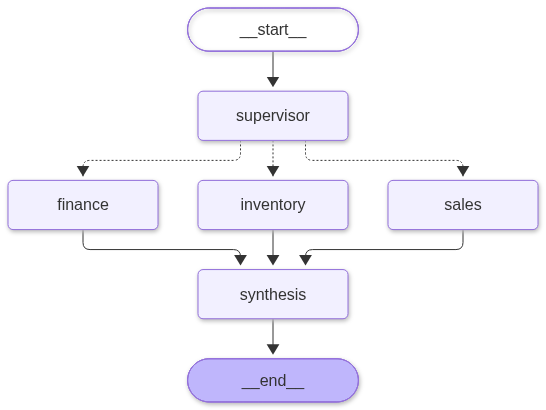

In [20]:
GRAPH

In [22]:
question = "Why did revenue decline in the West region in October 2026? Consider sales, stockouts, and margins."
result = analyze(question,"West","2026-10")


In [23]:
result

{'question': 'Why did revenue decline in the West region in October 2026? Consider sales, stockouts, and margins.',
 'region': 'West',
 'month': '2026-10',
 'selected': ['sales', 'inventory', 'finance'],
 'routing_reason': 'The question involves understanding revenue decline, which requires analyzing sales data (revenue and units), inventory data (stockouts), and finance data (gross profit, margin). Therefore, all three specialists are needed to investigate alternative hypotheses comprehensively.',
 'findings': [{'agent': 'sales',
   'analysis': 'In the West region for October 2026, revenue declined by 8.59% compared to the previous month. The decline was driven by all major product categories: Grocery revenue fell by 1.58%, Home by 5.68%, and Electronics by 22.09%. Units sold totaled 5,963, but the data does not provide specific information on stockouts or margins. The revenue drop correlates with lower sales across categories, especially Electronics, but no direct cause related to st

In [25]:
print("ANSWER:\n", result["answer"])

print("RECOMMENDATIONS:", *result["recommendations"],sep="\n - ")



ANSWER:
 In October 2026, the West region experienced an 8.59% revenue decline from $6,872,160 to $6,281,856. This decrease was observed across all major product categories: Grocery revenue fell by 1.58%, Home by 5.68%, and Electronics by 22.09%. Stockout data shows a total of 17 stockout days (Electronics 11, Home 4, Grocery 2), but this alone does not prove lost sales or directly explain the revenue decline. Financial data indicates gross profit decreased from $2,497,996.80 to $2,298,732.48, while gross margin percentage slightly increased from 36.35% to 36.59%. Promotion spend rose significantly from $288,630.72 to $471,139.20, increasing the promo rate from 4.2% to 7.5%. Although higher promotion costs coincided with revenue decline, no causal relationship is confirmed. Therefore, the revenue decline correlates with lower sales volumes, some stockouts, and increased promotion spend, but no definitive cause can be established from the available data.
RECOMMENDATIONS:
 - Collect deta